# 🏥 Notebook 04 — Percepções para Classificação

### Dataset: Cardiovascular Disease Prediction
### Disciplina: DCT1401 — Inteligência Artificial (UFRN)
### Aluna: Mariana dos Santos Batista Medeiros — Matrícula: 20230083988

Este notebook analisa o conjunto de dados preparado no Notebook 02 com foco no problema de **classificação**.

Nesta etapa serão realizadas:

1. Carregamento do dataset processado para classificação
2. Identificação e justificativa da variável alvo
3. Análise da distribuição das classes
4. Análise da relação entre as features e o target
5. Seleção de um conjunto reduzido de features prioritárias
6. Percepções, desafios e recomendações para modelagem

O objetivo deste notebook não é treinar um modelo definitivo, mas identificar quais variáveis parecem mais relevantes para um futuro problema de classificação.

In [1]:
# Manipulação de dados
import pandas as pd

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Testes estatísticos
from scipy import stats

# Organização dos caminhos do projeto
from pathlib import Path


# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 50)


# ---------------------------------------------------------
# Localização automática da raiz do projeto
# ---------------------------------------------------------

diretorio_atual = Path.cwd()

if diretorio_atual.name == "notebooks":
    raiz_projeto = diretorio_atual.parent

elif (diretorio_atual / "data" / "processed").exists():
    raiz_projeto = diretorio_atual

else:
    raise FileNotFoundError(
        "Não foi possível localizar a estrutura do projeto."
    )


# ---------------------------------------------------------
# Caminhos utilizados
# ---------------------------------------------------------

caminho_classificacao = (
    raiz_projeto
    / "data"
    / "processed"
    / "dataset_classification.csv"
)

pasta_figuras = raiz_projeto / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)


print("Bibliotecas carregadas com sucesso!")
print(f"Raiz do projeto: {raiz_projeto}")

Bibliotecas carregadas com sucesso!
Raiz do projeto: c:\Users\farma\OneDrive\Documentos\IA\projeto_cardiovascular


---
## 📁 1. Carregamento do Dataset Processado para Classificação

O Notebook 02 realizou a limpeza e o pré-processamento dos dados e gerou o arquivo `dataset_classification.csv`.

Essa versão contém as features já tratadas e codificadas, com as **16 variáveis quantitativas padronizadas pelo StandardScaler**. O arquivo mantém `Cardiovascular_Disease` como variável alvo da classificação e não inclui `Risk_Score`, conforme definido na etapa anterior.

As variáveis categóricas codificadas foram preservadas em suas representações numéricas e `Cardiovascular_Disease` permanece representada pelas classes 0 e 1.

Por isso, nenhum tratamento, codificação ou padronização será repetido neste notebook.

In [2]:
# Carregamento do dataset preparado no Notebook 02
df = pd.read_csv(caminho_classificacao)

print(
    f"Dataset carregado: "
    f"{df.shape[0]} linhas x {df.shape[1]} colunas"
)

print(
    "Valores ausentes:",
    df.isnull().sum().sum()
)

print(
    "Colunas textuais:",
    df.select_dtypes(include="object").columns.tolist()
)

print(
    "Cardiovascular_Disease presente:",
    "Cardiovascular_Disease" in df.columns
)

print(
    "Risk_Score presente:",
    "Risk_Score" in df.columns
)

df.head()

Dataset carregado: 20000 linhas x 36 colunas
Valores ausentes: 0
Colunas textuais: []
Cardiovascular_Disease presente: True
Risk_Score presente: False


,Age,Gender,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Diabetes,Hypertension,Smoking,Alcohol_Consumption,Physical_Activity,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Stress_Level,Family_History,Chest_Pain,Shortness_of_Breath,ECG_Result,Medication,Diet_Quality,Annual_Income_USD,Education_Level,BMI_Category,Cardiovascular_Disease,Region_East,Region_North,Region_South,Region_West
0,-0.604930,0,-0.244301,1.136970,1.085015,-0.384491,-0.050595,1.052636,1.090643,-0.722347,-0.020672,1.838329,-0.454229,0,0,1,0,1,1.528986,-0.107776,1.170423,2,0,0,0,0,0,1,0.056754,1,3,0,0,0,0,0
1,-0.499972,0,-0.496768,-2.173125,-1.762031,-0.611338,-2.090550,-0.149747,0.356960,0.238860,-0.704551,0.448452,-1.105517,0,0,0,0,1,-0.660033,-0.511923,-0.005464,0,0,0,1,0,0,0,-1.379411,2,0,0,0,1,0,0
2,-0.814846,0,-1.415746,1.623351,2.402790,0.125914,-0.475586,-0.650740,0.356960,-2.164156,-0.377479,1.416088,0.450336,0,0,1,1,0,0.653378,0.642783,0.543283,1,0,0,0,0,0,0,-0.992920,1,3,0,0,0,1,0
3,1.494228,0,0.068757,0.042612,-0.037535,0.693031,0.629390,-0.450342,-1.287500,-0.379059,-0.526148,0.993847,-0.020038,1,0,1,0,1,0.215575,1.479945,0.778461,1,1,1,1,0,1,1,1.229963,1,2,1,0,0,0,1
4,-1.077241,0,0.876650,-1.288181,-1.436654,1.090013,-0.050595,-0.851137,0.508757,0.238860,-0.704551,-0.255282,0.558884,0,1,1,0,1,0.653378,-0.107776,-0.397426,1,1,0,0,0,1,1,-0.254270,0,0,0,0,0,0,1


> **Observação:** valores negativos que possam aparecer nas variáveis quantitativas não representam valores físicos negativos. Eles resultam da padronização pelo StandardScaler: valores abaixo da média da variável ficam negativos e valores acima da média ficam positivos. O target `Cardiovascular_Disease` permanece representado pelas classes 0 e 1.

---
## 🎯 2. Identificação e Justificativa da Variável Alvo

### Variável escolhida: `Cardiovascular_Disease`

A variável `Cardiovascular_Disease` foi escolhida como target para o problema de classificação pelos seguintes motivos:

**1. Natureza da variável:** é uma variável binária, codificada como 0 e 1, sendo naturalmente compatível com um problema de classificação binária.

**2. Não exige discretização:** como as classes já estão definidas no próprio conjunto de dados, não é necessário transformar uma variável contínua em categorias.

**3. Coerência com o problema:** a variável representa uma classificação binária associada à doença cardiovascular, sendo adequada como resultado a ser previsto a partir das demais características.

**4. Relação com as features:** nas próximas seções serão utilizadas visualizações e testes estatísticos para investigar quais características apresentam maior associação com o target.

A escolha é, portanto, baseada na natureza categórica da variável e no significado que ela possui dentro do conjunto de dados.

---
## ⚖️ 3. Análise de Balanceamento de Classes

### 3.1 Distribuição das classes

In [3]:
# Contagem e proporção
contagem = df["Cardiovascular_Disease"].value_counts()
proporcao = df["Cardiovascular_Disease"].value_counts(normalize=True) * 100

print("Distribuição da variável Cardiovascular_Disease:")
print("=" * 50)
print(f"Classe 0: {contagem[0]} registros ({proporcao[0]:.1f}%)")
print(f"Classe 1: {contagem[1]} registros ({proporcao[1]:.1f}%)")
print(f"\nRazão de desbalanceamento: {contagem[0]/contagem[1]:.2f}:1")

Distribuição da variável Cardiovascular_Disease:
Classe 0: 13880 registros (69.4%)
Classe 1: 6120 registros (30.6%)

Razão de desbalanceamento: 2.27:1


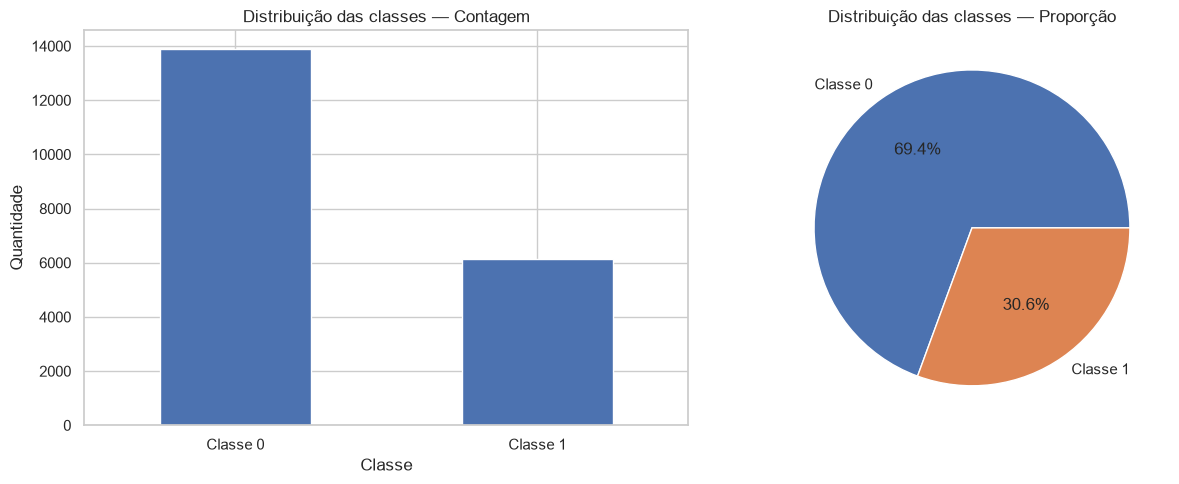

In [4]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# Barras
contagem.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Distribuição das classes — Contagem")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Quantidade")
axes[0].set_xticklabels(
    ["Classe 0", "Classe 1"],
    rotation=0
)

# Pizza
contagem.plot(
    kind="pie",
    ax=axes[1],
    autopct="%1.1f%%",
    labels=["Classe 0", "Classe 1"]
)

axes[1].set_title("Distribuição das classes — Proporção")
axes[1].set_ylabel("")

plt.tight_layout()

plt.savefig(
    pasta_figuras / "class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

> 💡 **Interpretação:** A classe 0 representa aproximadamente 69,4% dos registros e a classe 1 aproximadamente 30,6%, resultando em uma razão de cerca de 2,27:1.
>
> Existe, portanto, um desbalanceamento entre as classes, embora a classe minoritária ainda represente parcela relevante do conjunto. Em uma futura etapa de modelagem, essa característica deverá ser considerada na divisão dos dados e na escolha das métricas de avaliação.

---
## 📊 4. Relação entre Features e Target

### 4.1 Teste ANOVA — Features quantitativas

Para investigar quais features quantitativas apresentam diferenças mais evidentes entre as classes de `Cardiovascular_Disease`, será utilizado o teste ANOVA.

As 16 features quantitativas já foram padronizadas pelo `StandardScaler` no Notebook 02. Essa transformação altera a escala dos valores, mas não altera o resultado da estatística F da ANOVA, pois a padronização consiste em uma transformação linear aplicada igualmente aos grupos.

Consequentemente, as médias apresentadas nesta análise estarão expressas em **valores padronizados (Z-score)**, enquanto o ranking das features pela estatística F permanece equivalente ao obtido antes da padronização.

In [5]:
features_quantitativas = [
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Heart_Rate",
    "Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Blood_Glucose",
    "Exercise_Days_Per_Week",
    "Daily_Walking_Minutes",
    "Sleep_Hours",
    "Annual_Income_USD"
]

grupo_0 = df[
    df["Cardiovascular_Disease"] == 0
]

grupo_1 = df[
    df["Cardiovascular_Disease"] == 1
]

resultados_anova = []

for feature in features_quantitativas:

    f_stat, p_val = stats.f_oneway(
        grupo_0[feature],
        grupo_1[feature]
    )

    resultados_anova.append({
        "Feature": feature,
        "F-statistic": f_stat,
        "p-value": p_val,
        "Média padronizada classe 0": grupo_0[feature].mean(),
        "Média padronizada classe 1": grupo_1[feature].mean()
    })

df_anova = (
    pd.DataFrame(resultados_anova)
    .sort_values(
        "F-statistic",
        ascending=False
    )
)

display(
    df_anova
    .head(10)
    .round(3)
)

,Feature,F-statistic,p-value,Média padronizada classe 0,Média padronizada classe 1
11,Blood_Glucose,1044.788,0.0,-0.148,0.336
4,Blood_Pressure_Systolic,906.526,0.0,-0.138,0.314
0,Age,306.283,0.0,-0.082,0.185
3,BMI,215.913,0.0,-0.069,0.156
2,Weight_kg,163.403,0.0,-0.060,0.136
7,Cholesterol,160.504,0.0,-0.059,0.134
9,LDL,130.012,0.0,-0.053,0.121
8,HDL,119.532,0.0,0.051,-0.116
12,Exercise_Days_Per_Week,85.117,0.0,0.043,-0.098
13,Daily_Walking_Minutes,43.690,0.0,0.031,-0.070


> 💡 **Interpretação:** Entre as features quantitativas, `Blood_Glucose` e `Blood_Pressure_Systolic` apresentam os maiores valores da estatística F, seguidas por `Age`, `BMI`, `Weight_kg` e `Cholesterol`.
>
> Valores de p muito baixos indicam evidência de diferença entre as médias das classes. Entretanto, significância estatística não deve ser interpretada isoladamente como garantia de alto poder preditivo, especialmente em um conjunto com grande número de observações.
>
> **Observação:** valores de p exibidos como `0.000` correspondem a valores extremamente pequenos na precisão apresentada e não devem ser interpretados como p-valor literalmente igual a zero.

### 4.2 Boxplots das features quantitativas com maior associação

Os boxplots permitem comparar a distribuição das features quantitativas entre as duas classes. Como essas variáveis foram padronizadas no Notebook 02, o eixo vertical apresenta os valores em **escala padronizada (Z-score)**.

In [6]:
top6_quantitativas = (
    df_anova
    .head(6)["Feature"]
    .tolist()
)

print(
    "Features quantitativas selecionadas:",
    top6_quantitativas
)

Features quantitativas selecionadas: ['Blood_Glucose', 'Blood_Pressure_Systolic', 'Age', 'BMI', 'Weight_kg', 'Cholesterol']


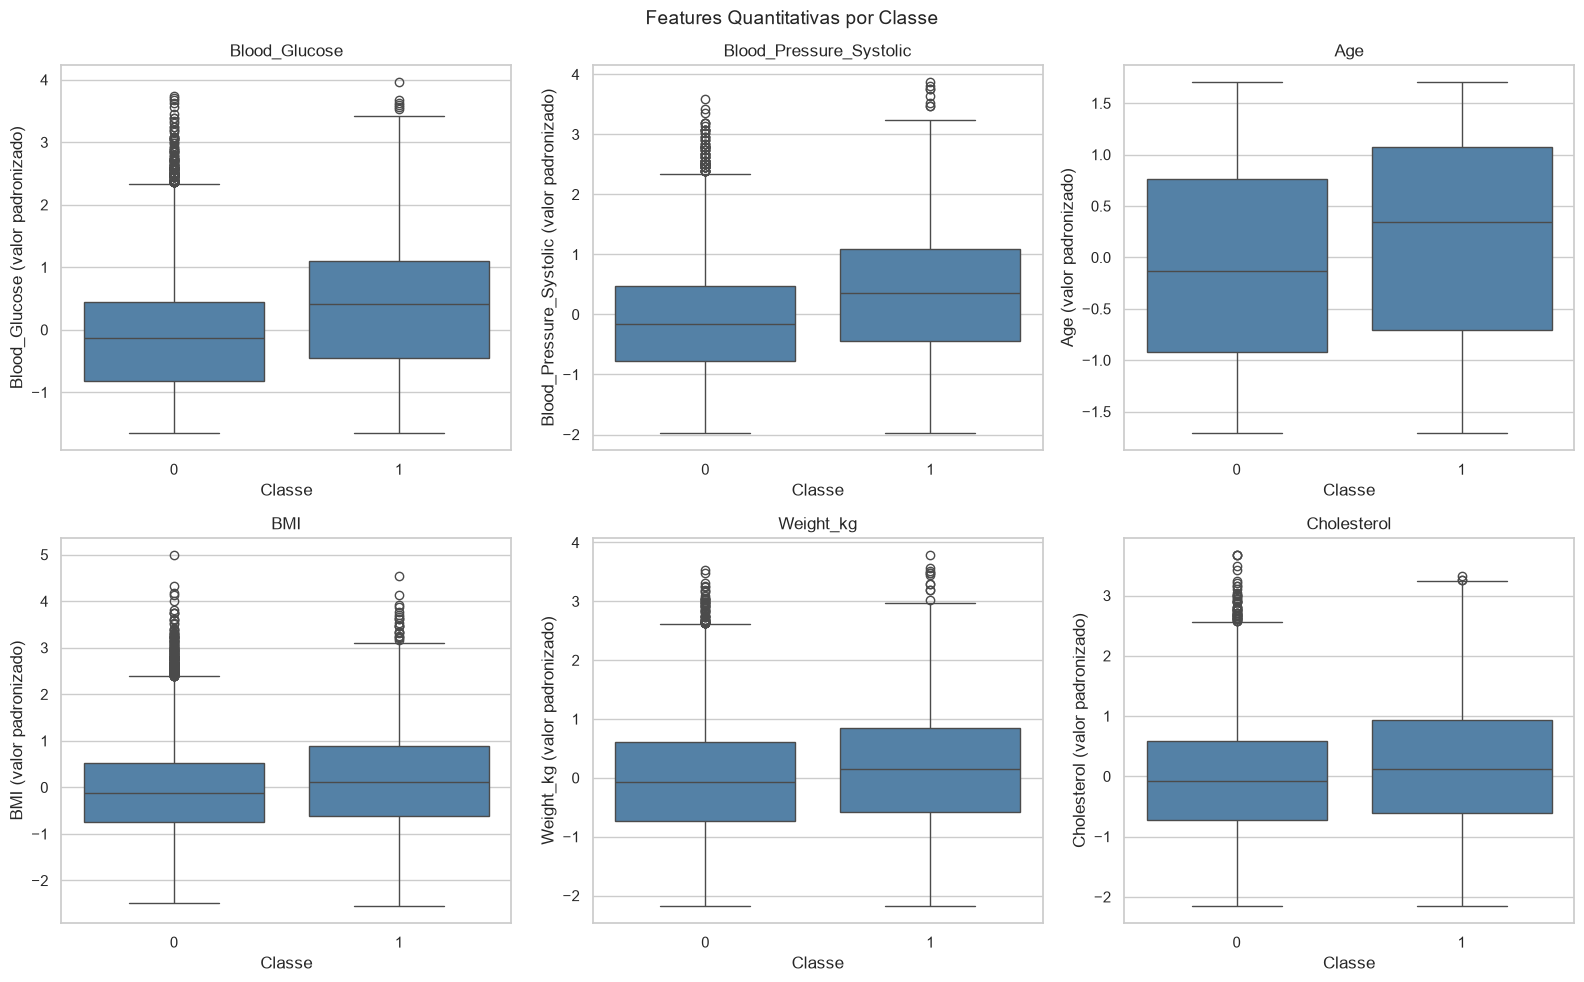

In [7]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

for ax, feature in zip(
    axes.ravel(),
    top6_quantitativas
):

    sns.boxplot(
        data=df,
        x="Cardiovascular_Disease",
        y=feature,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(feature)
    ax.set_xlabel("Classe")
    ax.set_ylabel(f"{feature} (valor padronizado)")

plt.suptitle(
    "Features Quantitativas por Classe",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "boxplot_features_by_class.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 4.3 Teste Qui-Quadrado — Features categóricas

O teste Qui-Quadrado será utilizado para avaliar a existência de associação entre as features categóricas e `Cardiovascular_Disease`.

Embora essas variáveis já estejam representadas numericamente após a codificação realizada no Notebook 02, seus valores são tratados nesta análise como **categorias**, por meio das tabelas de contingência utilizadas no teste Qui-Quadrado.


In [8]:
features_categoricas = [
    "Gender",
    "Diabetes",
    "Hypertension",
    "Smoking",
    "Alcohol_Consumption",
    "Physical_Activity",
    "Stress_Level",
    "Family_History",
    "Chest_Pain",
    "Shortness_of_Breath",
    "ECG_Result",
    "Medication",
    "Diet_Quality",
    "Education_Level",
    "BMI_Category",
    "Region_East",
    "Region_North",
    "Region_South",
    "Region_West"
]

resultados_chi2 = []

for feature in features_categoricas:

    tabela = pd.crosstab(
        df[feature],
        df["Cardiovascular_Disease"]
    )

    chi2, p_val, dof, expected = (
        stats.chi2_contingency(tabela)
    )

    resultados_chi2.append({
        "Feature": feature,
        "Chi2": chi2,
        "p-value": p_val,
        "Significativo?":
            "Sim" if p_val < 0.05 else "Não"
    })

df_chi2 = (
    pd.DataFrame(resultados_chi2)
    .sort_values(
        "Chi2",
        ascending=False
    )
)

display(
    df_chi2
    .round(3)
)

,Feature,Chi2,p-value,Significativo?
1,Diabetes,1730.677,0.000,Sim
2,Hypertension,1496.828,0.000,Sim
8,Chest_Pain,1011.569,0.000,Sim
10,ECG_Result,1008.320,0.000,Sim
5,Physical_Activity,578.664,0.000,Sim
7,Family_History,486.235,0.000,Sim
3,Smoking,444.162,0.000,Sim
6,Stress_Level,420.611,0.000,Sim
9,Shortness_of_Breath,358.267,0.000,Sim
14,BMI_Category,351.596,0.000,Sim



> 💡 **Interpretação:** `Diabetes`, `Hypertension`, `Chest_Pain` e `ECG_Result` apresentam os maiores valores do teste Qui-Quadrado, indicando as associações mais fortes entre as features categóricas analisadas e `Cardiovascular_Disease`.
>
> Outras variáveis também apresentam associação estatisticamente significativa, enquanto algumas não demonstraram evidência de associação ao nível de 5%. O p-value indica evidência estatística de associação, mas não deve ser interpretado isoladamente como medida de poder preditivo.
>
> **Observação:** valores de p exibidos como `0.000` correspondem a valores extremamente pequenos na precisão apresentada e não devem ser interpretados como p-value literalmente igual a zero.

### 4.4 Distribuição das principais features categóricas por classe

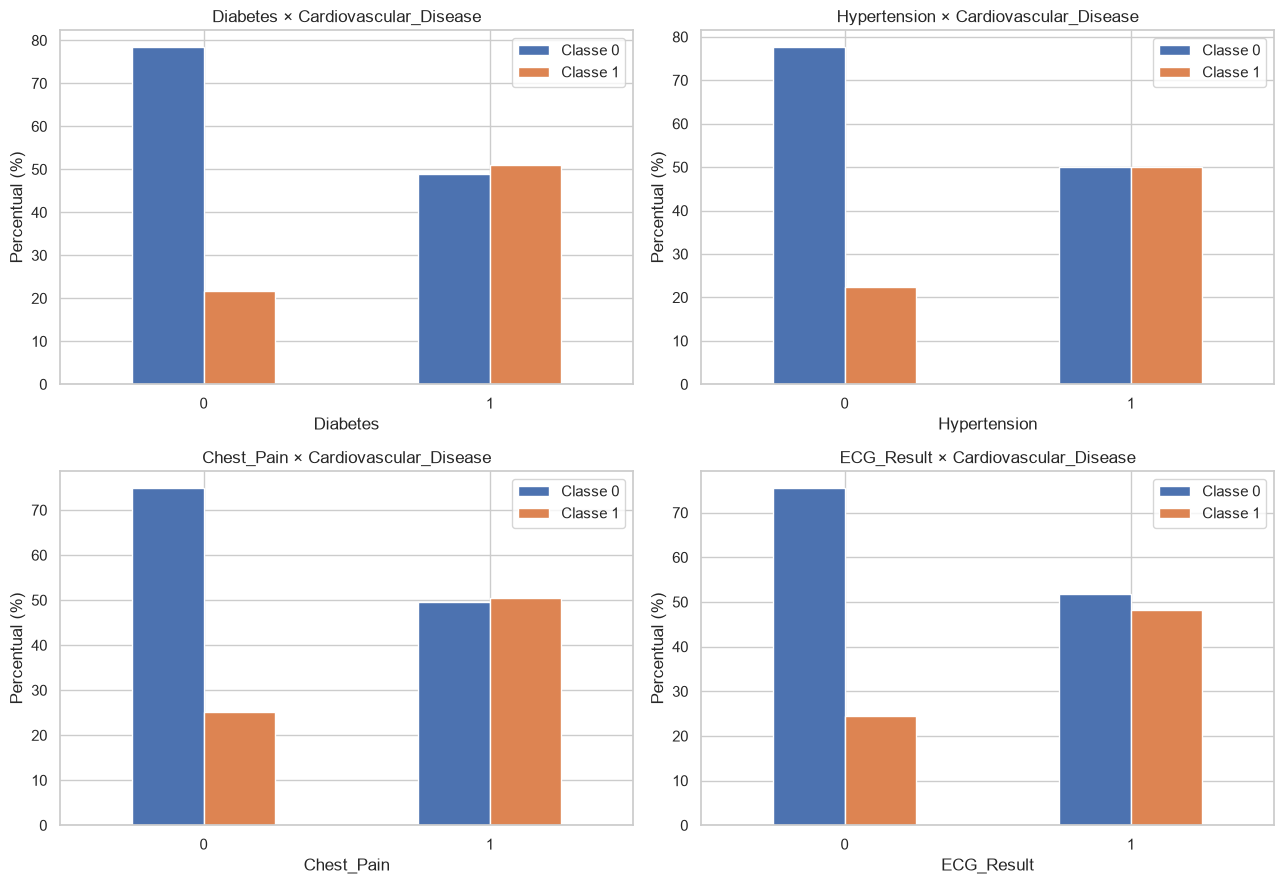

In [9]:
features_cat_destaque = [
    "Diabetes",
    "Hypertension",
    "Chest_Pain",
    "ECG_Result"
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9)
)

for ax, feature in zip(
    axes.ravel(),
    features_cat_destaque
):

    tabela_percentual = (
        pd.crosstab(
            df[feature],
            df["Cardiovascular_Disease"],
            normalize="index"
        )
        * 100
    )

    tabela_percentual.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(
        f"{feature} × Cardiovascular_Disease"
    )

    ax.set_ylabel("Percentual (%)")
    ax.set_xlabel(feature)
    ax.tick_params(
        axis="x",
        rotation=0
    )

    ax.legend(
        ["Classe 0", "Classe 1"]
    )

plt.tight_layout()

plt.savefig(
    pasta_figuras / "categorical_vs_disease.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

---
## 🔎 5. Seleção das Features Prioritárias

A análise das relações entre features e target permitiu identificar as variáveis que mais se destacaram nos testes estatísticos.

Para manter um conjunto reduzido e representativo de variáveis nas próximas etapas, foram selecionadas:

- as **duas features quantitativas** com maiores estatísticas F na ANOVA;
- as **quatro features categóricas** com maiores estatísticas no teste Qui-Quadrado.

Essa estratégia mantém um conjunto enxuto, fundamentado nos resultados obtidos e composto por diferentes tipos de informação.

In [10]:
top2_quantitativas = (
    df_anova
    .head(2)["Feature"]
    .tolist()
)

top4_categoricas = (
    df_chi2
    .head(4)["Feature"]
    .tolist()
)

features_prioritarias = (
    top4_categoricas
    + top2_quantitativas
)

print(
    "Features categóricas prioritárias:",
    top4_categoricas
)

print(
    "Features quantitativas prioritárias:",
    top2_quantitativas
)

print(
    "\nConjunto final:",
    features_prioritarias
)

Features categóricas prioritárias: ['Diabetes', 'Hypertension', 'Chest_Pain', 'ECG_Result']
Features quantitativas prioritárias: ['Blood_Glucose', 'Blood_Pressure_Systolic']

Conjunto final: ['Diabetes', 'Hypertension', 'Chest_Pain', 'ECG_Result', 'Blood_Glucose', 'Blood_Pressure_Systolic']


> 💡 **Features prioritárias:** `Diabetes`, `Hypertension`, `Chest_Pain`, `ECG_Result`, `Blood_Glucose` e `Blood_Pressure_Systolic`.
>
> A seleção combina as features categóricas e quantitativas que mais se destacaram nos testes estatísticos realizados. O objetivo é manter um conjunto reduzido e fundamentado nos dados para orientar análises posteriores.
>
> Essa seleção é exploratória e não implica que as demais features sejam irrelevantes.

---
## 📝 6. Percepções e Recomendações para Modelagem — Classificação

### Features recomendadas

Considerando os resultados da ANOVA e do teste Qui-Quadrado e a necessidade de manter um conjunto enxuto de variáveis, recomenda-se inicialmente:

- `Diabetes`
- `Hypertension`
- `Chest_Pain`
- `ECG_Result`
- `Blood_Glucose`
- `Blood_Pressure_Systolic`

As quatro primeiras apresentaram as maiores associações entre as features categóricas analisadas, enquanto `Blood_Glucose` e `Blood_Pressure_Systolic` apresentaram os maiores valores da estatística F entre as features quantitativas.

A seleção fornece um conjunto reduzido e fundamentado nos dados para orientar análises e modelagens posteriores.

### Possíveis desafios

**1. Desbalanceamento das classes:** o target apresenta aproximadamente 69,4% de registros na classe 0 e 30,6% na classe 1. Esse desbalanceamento deve ser considerado na avaliação de futuros modelos.

**2. Avaliação do desempenho:** a acurácia isoladamente pode não representar adequadamente o desempenho sobre a classe minoritária. Métricas como Precision, Recall, F1-Score e ROC-AUC devem ser consideradas em conjunto.

### Algoritmos sugeridos

| Algoritmo | Justificativa |
|---|---|
| **Regressão Logística** | Modelo inicial simples e interpretável para classificação binária |
| **Random Forest Classifier** | Permite representar relações não lineares e interações entre features |
| **Gradient Boosting Classifier** | Alternativa para relações mais complexas entre as variáveis |
| **SVM** | Algoritmo sensível à escala; o dataset utilizado já possui as features quantitativas padronizadas pelo StandardScaler |

### Métricas sugeridas

| Métrica | Objetivo |
|---|---|
| **Accuracy** | Proporção total de classificações corretas |
| **Precision** | Proporção de positivos previstos que pertencem à classe positiva |
| **Recall** | Proporção da classe positiva corretamente identificada |
| **F1-Score** | Equilíbrio entre Precision e Recall |
| **ROC-AUC** | Capacidade de discriminação do classificador entre as classes |

Em uma futura etapa de modelagem, recomenda-se utilizar divisão estratificada entre treino e teste ou validação cruzada estratificada para preservar a proporção das classes durante a avaliação.

Em síntese, Cardiovascular_Disease mostrou-se adequado como target para o problema de classificação, e os testes realizados destacaram Diabetes, Hypertension, Chest_Pain, ECG_Result, Blood_Glucose e Blood_Pressure_Systolic como features prioritárias. O desbalanceamento entre as classes deve ser considerado na avaliação dos modelos, evitando o uso isolado da acurácia. Como alternativas iniciais, podem ser avaliados Regressão Logística, Random Forest Classifier, Gradient Boosting Classifier e SVM, utilizando métricas como Precision, Recall, F1-Score e ROC-AUC.